In [175]:
import scanpy as sc
import pyarrow.parquet as pa
import pandas as pd

### Problem 1: Load, attach location, QC
Load data\Breast\outs\cell_feature_matrix.h5 into an AnnData object. Add each cell's X/Y from cells.parquet, checking the cell IDs line up. Then decide on a QC threshold for low-quality cells.

- Why: this makes your "QC for low counts" instinct concrete. You'll pick and defend a real number. 
- Where to look: scanpy's 10x reader functions; sc.pp.calculate_qc_metrics; what adata.obs and adata.obsm are for; and how to plot cells using their spatial coordinates.
- Before you plot, predict: will the cells you filter out be scattered randomly across the tissue, or bunched in certain places? 
- Done when: you can say how many cells you removed and why you chose that threshold, and you have a spatial plot of the removed cells that confirms or contradicts your prediction.

In [185]:
matrix = sc.read_10x_h5(r"data\Breast\outs\cell_feature_matrix.h5")
matrix.obs.index.name = "cell_id"

In [186]:
cells = pd.read_parquet(r"data\Breast\outs\cells.parquet")

In [187]:
cells["cell_id"] = cells["cell_id"].str.decode("ascii")

In [188]:
matrix.obs = pd.merge(matrix.obs,cells,how="inner",on="cell_id")

C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [189]:
import numpy as np
matrix.obsm["spatial"] = np.transpose(np.array((matrix.obs["x_centroid"],matrix.obs["y_centroid"])))

In [ ]:
np.array_equal(matrix.obs["cell_id"].to_numpy(), cells["cell_id"].to_numpy())


True

In [ ]:
matrix.shape[1]

380

In [195]:
sc.pp.calculate_qc_metrics(matrix,expr_type="counts",percent_top=[300],inplace=True)

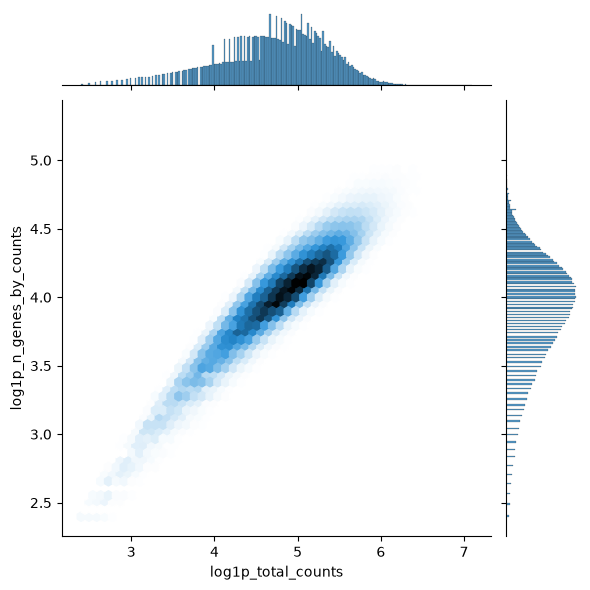

In [196]:
import seaborn as sns
sns.jointplot(
    data=matrix.obs,
    x="log1p_total_counts",
    y="log1p_n_genes_by_counts",
    kind="hex",
)

In [200]:
sc.pp.filter_cells(matrix,min_genes=10,inplace=True)
sc.pp.filter_genes(matrix, min_cells=3,inplace=True)

In [183]:
sc.pl.spatial(matrix, color="log1p_n_genes_by_counts")

C:\Users\MilesBailey\AppData\Local\Temp\ipykernel_15016\2918091537.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(matrix, color="log1p_n_genes_by_counts")


ValueError: When .uns['spatial'][library_id] does not exist, spot_size must be provided directly.

In [198]:
matrix.obs

,cell_id,x_centroid,y_centroid,transcript_counts,control_probe_counts,control_codeword_counts,unassigned_codeword_counts,total_counts,cell_area,nucleus_area,n_genes,n_genes_by_counts,log1p_n_genes_by_counts,log1p_total_counts,pct_counts_in_top_300_genes
0,aaaabecc-1,847.939590,860.676932,57,0,0,0,57.0,277.936719,29.216094,42,42,3.761200,4.060443,100.0
1,aaaabggh-1,831.635559,865.314319,88,0,0,0,88.0,687.955469,37.840938,49,49,3.912023,4.488636,100.0
2,aaaacpcd-1,1655.837872,8794.647021,190,0,0,0,190.0,223.342813,29.216094,85,85,4.454347,5.252274,100.0
3,aaaaeclm-1,1645.499042,8798.733496,146,0,0,0,146.0,96.995625,21.900781,53,53,3.988984,4.990433,100.0
4,aaaaiale-1,1653.466339,8805.801611,203,0,0,0,203.0,115.012969,44.162813,68,68,4.234107,5.318120,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
576958,oiknppjn-1,8352.258545,2564.133533,90,0,0,0,90.0,50.981406,31.654531,44,44,3.806662,4.510859,100.0
576959,oikobelc-1,8348.388721,2577.497168,96,0,0,0,96.0,47.007656,32.106094,45,45,3.828641,4.574711,100.0
576960,oikodiap-1,8348.098193,2569.456201,178,0,0,0,178.0,90.222188,59.741719,63,63,4.158883,5.187386,100.0
576961,oikodnab-1,8347.592676,2589.846033,50,0,0,0,50.0,83.584219,13.953281,34,34,3.555348,3.931826,100.0


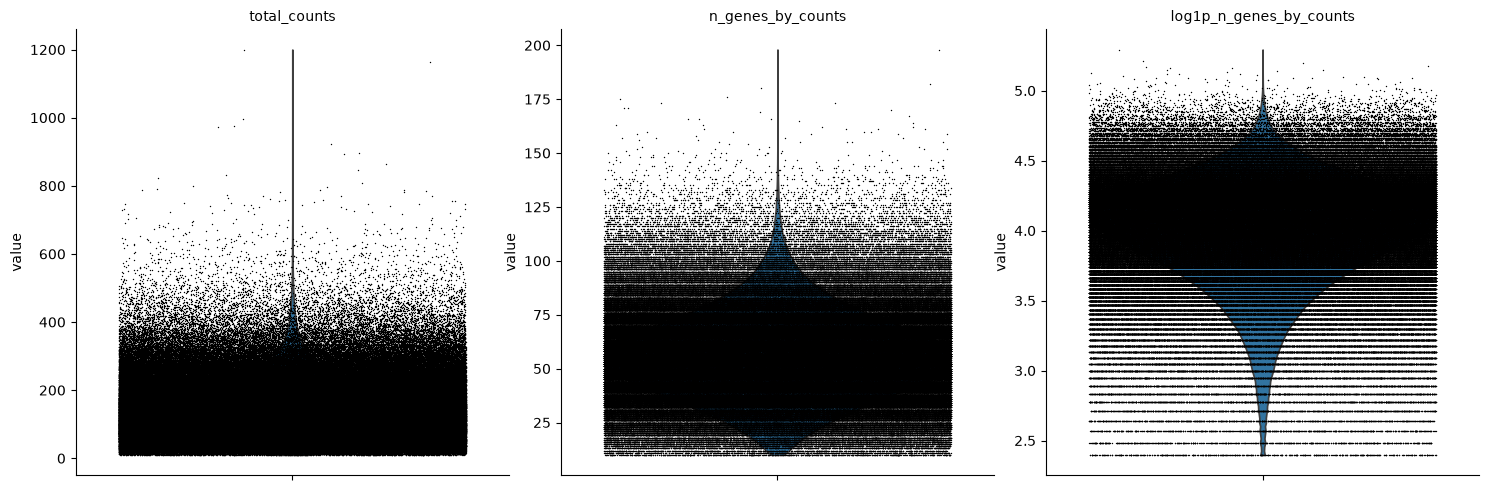

In [199]:
sc.pl.violin(
    matrix,
    ["total_counts","n_genes_by_counts","log1p_n_genes_by_counts"],
    jitter=0.4,
    multi_panel=True,
)

### Problem 2: What does Leiden actually cluster?
Normalise and log-transform. Then work out from scanpy's documentation what input Leiden actually runs on, tracing it back step by step.

- Why: this is the shaky "what's between the normalised matrix and the clusters" area, and it resolves the UMAP question with evidence rather than my say-so.
- Where to look: the docs for sc.tl.leiden, sc.pp.neighbors and sc.tl.pca, especially which data each one reads. Also look up why scRNA-seq workflows select "highly variable genes", then ask whether that reasoning still applies to a hand-picked 380-gene panel.
- Done when: you can draw the pipeline as a chain of arrows, raw counts → … → clusters, and say where UMAP branches off and why it's a side branch.

In [201]:
# Saving count data
matrix.layers["counts"] = matrix.X.copy()

# Normalizing to median total counts
sc.pp.normalize_total(matrix)
# Logarithmize the data
sc.pp.log1p(matrix)

In [210]:
sc.pp.highly_variable_genes(matrix, n_top_genes=400)

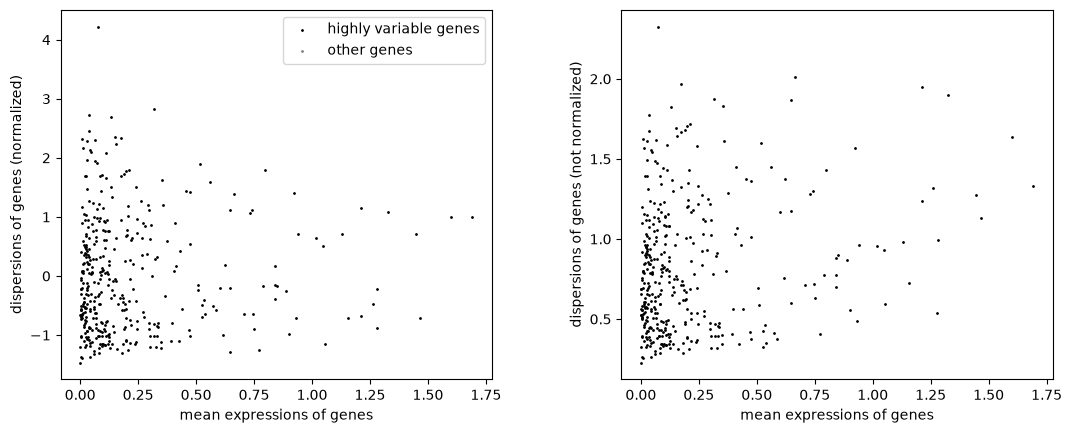

In [211]:
sc.pl.highly_variable_genes(matrix)

In [212]:
sc.tl.pca(matrix)

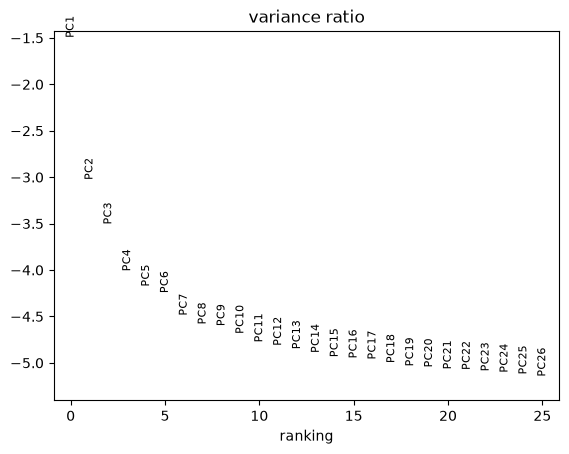

In [213]:
sc.pl.pca_variance_ratio(matrix, n_pcs=25, log=True)

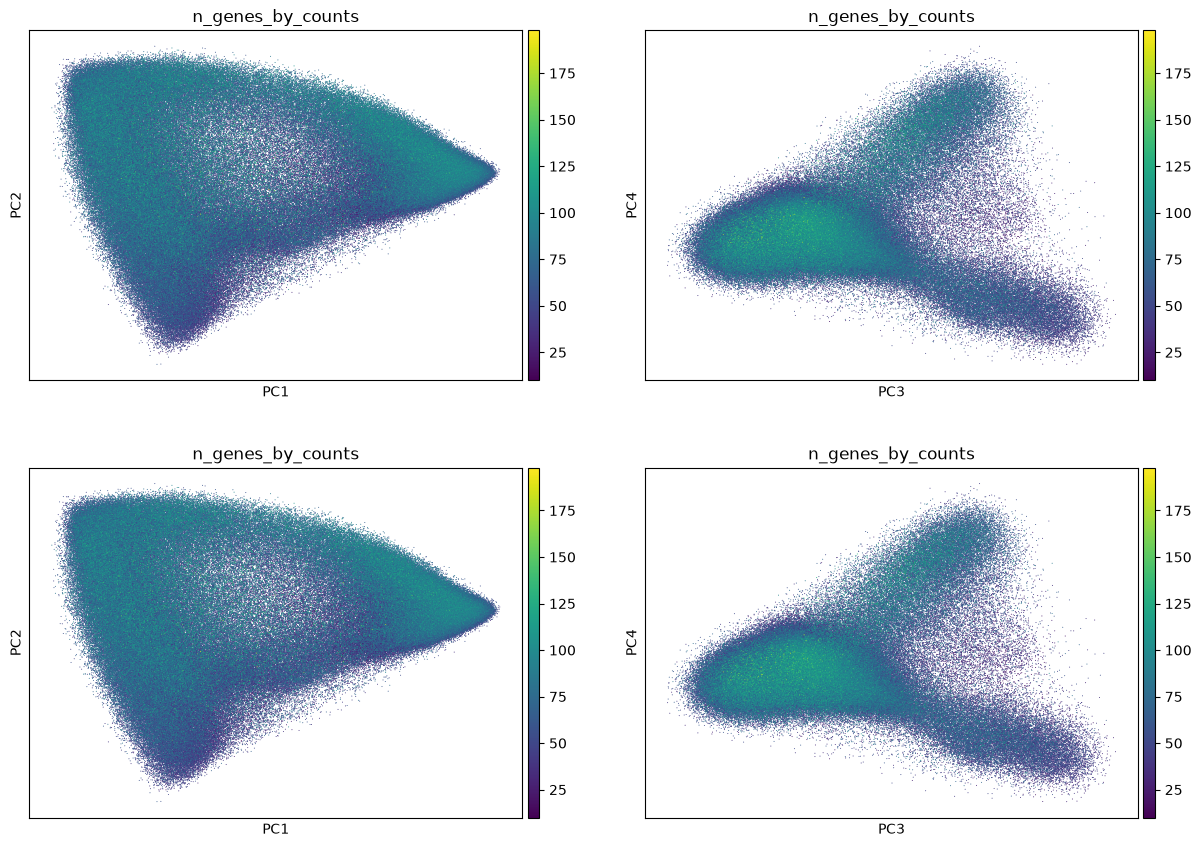

In [215]:
sc.pl.pca(
    matrix,
    color=["n_genes_by_counts"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)

In [214]:
matrix.obs

,cell_id,x_centroid,y_centroid,transcript_counts,control_probe_counts,control_codeword_counts,unassigned_codeword_counts,total_counts,cell_area,nucleus_area,n_genes,n_genes_by_counts,log1p_n_genes_by_counts,log1p_total_counts,pct_counts_in_top_300_genes
0,aaaabecc-1,847.939590,860.676932,57,0,0,0,57.0,277.936719,29.216094,42,42,3.761200,4.060443,100.0
1,aaaabggh-1,831.635559,865.314319,88,0,0,0,88.0,687.955469,37.840938,49,49,3.912023,4.488636,100.0
2,aaaacpcd-1,1655.837872,8794.647021,190,0,0,0,190.0,223.342813,29.216094,85,85,4.454347,5.252274,100.0
3,aaaaeclm-1,1645.499042,8798.733496,146,0,0,0,146.0,96.995625,21.900781,53,53,3.988984,4.990433,100.0
4,aaaaiale-1,1653.466339,8805.801611,203,0,0,0,203.0,115.012969,44.162813,68,68,4.234107,5.318120,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
576958,oiknppjn-1,8352.258545,2564.133533,90,0,0,0,90.0,50.981406,31.654531,44,44,3.806662,4.510859,100.0
576959,oikobelc-1,8348.388721,2577.497168,96,0,0,0,96.0,47.007656,32.106094,45,45,3.828641,4.574711,100.0
576960,oikodiap-1,8348.098193,2569.456201,178,0,0,0,178.0,90.222188,59.741719,63,63,4.158883,5.187386,100.0
576961,oikodnab-1,8347.592676,2589.846033,50,0,0,0,50.0,83.584219,13.953281,34,34,3.555348,3.931826,100.0


In [216]:
sc.pp.neighbors(matrix)

c:\Users\MilesBailey\Documents\GitHub\Spatial-Cell-Classifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [217]:
sc.tl.umap(matrix)

In [219]:
# Using the igraph implementation and a fixed number of iterations can be significantly faster,
# especially for larger datasets
sc.tl.leiden(matrix, flavor="igraph", n_iterations=2)

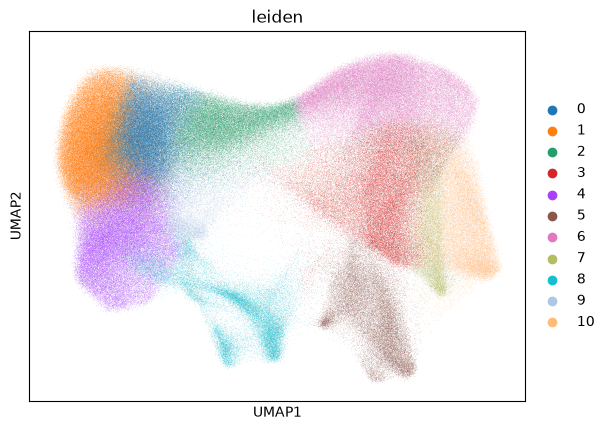

In [220]:
sc.pl.umap(matrix, color=["leiden"])

In [ ]:
sc.pl.umap(
    matrix,
    color=["leiden", "", "doublet_score"],
    # increase horizontal space between panels
    wspace=0.5,
    size=3,
)

### Problem 3: Name your clusters and check them
Run Leiden at two different resolutions. Find marker genes per cluster and give each cluster a cell type name. Then compare your names against the paper's labels (cells_final_label_group in data\sthelar\labels\breast_s0_cell_metadata.parquet; remember row N matches row N).

- Why: this targets "how many clusters?" and "how do I know they're any good?"
- Where to look: sc.tl.rank_genes_groups; marker gene lists for breast tissue cell types (epithelial, fibroblast, immune subtypes, endothelial); and pd.crosstab for the comparison.
- Done when: you can say which of your clusters agree with the paper, which disagree, and give at least one reason a disagreement might be their mistake rather than yours.